# Guardar el ES contra underflow silencioso

Pregunta: ¿se puede detectar una pérdida numérica y recalcular desde los inputs originales? Hipótesis: los fallbacks coinciden con el oráculo racional y el camino ordinario conserva el baseline. Los métodos son conocidos; el aporte es el guard, sus políticas y el benchmark del repo. Pérdidas positivas, pesos conocidos y valores interpretados en binary64.

In [1]:
from src.guard import guarded_tail, TailUnderflowError
from src.sources import legacy
x, p = [1e308, 0.0], [1e-300, 1e300]
print('Baseline:', legacy.weighted_tail(x, .975, p).es)
r = guarded_tail(x, .975, p)
print('Protegido:', r.es, r.backend, r.fallback_reason)
assert r.es > 0
try:
    guarded_tail(x, .975, p, policy='raise')
except TailUnderflowError as error:
    print('Rechazo explícito:', error)

Baseline: 0.0
Protegido: 3.999999999999996e-291 fraction underflow encountered in divide
Rechazo explícito: underflow encountered in divide


## Experimento ejecutado

Se reutilizan 207 fixtures del aporte C++ y se añade un barrido de exponentes. El baseline real queda sin modificar. La referencia hinge usa Fraction sobre inputs binarios exactos; el fallback integra masa de cola en racionales. No son dos copias del mismo algoritmo.

In [2]:
import json, csv
from pathlib import Path
m=json.loads(Path('results/metadata.json').read_text())
print(m['summary'])
assert m['summary']['guard_lost_representable'] == 0
rows=list(csv.DictReader(Path('results/accuracy.csv').open()))
for row in rows:
    if row['reference_rounds_to_zero'] == 'True':
        print('Resultado no representable:', row['id'], row['output_rounds_to_zero'])

{'fixtures': 388, 'fallbacks': 107, 'baseline_lost_representable': 78, 'guard_lost_representable': 0, 'unrepresentable_final': 29, 'performance_rows': 168}
Resultado no representable: 262 True
Resultado no representable: 287 True
Resultado no representable: 292 True
Resultado no representable: 293 True
Resultado no representable: 312 True
Resultado no representable: 317 True
Resultado no representable: 318 True
Resultado no representable: 322 True
Resultado no representable: 323 True
Resultado no representable: 337 True
Resultado no representable: 342 True
Resultado no representable: 343 True
Resultado no representable: 347 True
Resultado no representable: 348 True
Resultado no representable: 352 True
Resultado no representable: 353 True
Resultado no representable: 354 True
Resultado no representable: 362 True
Resultado no representable: 367 True
Resultado no representable: 368 True
Resultado no representable: 372 True
Resultado no representable: 373 True
Resultado no representable: 37

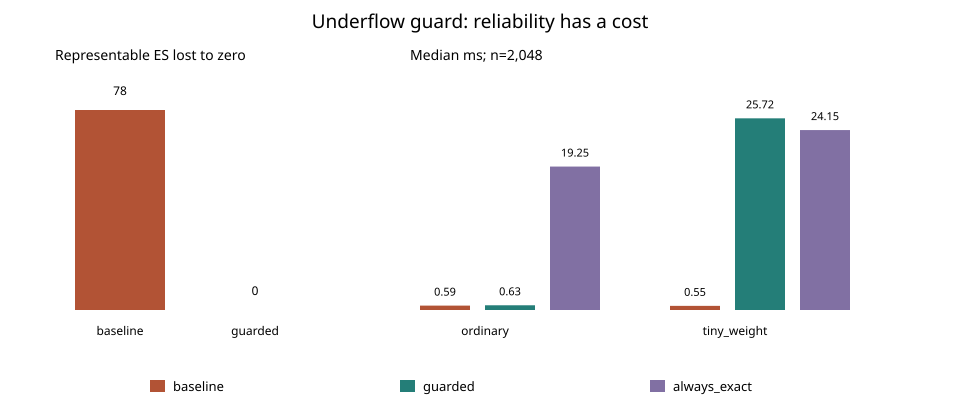

In [3]:
from IPython.display import SVG, display
display(SVG(filename='results/comparison.svg'))

## Conclusión crítica

La exactitud del fallback tiene costo: siempre-exacto es la ablación de velocidad. El guard no promete detectar todo error de redondeo. El presupuesto limita el fallback a 4096 filas; casos mayores se rechazan. Un ES racional no nulo puede redondear a cero al devolver float: se declara con un flag y se conserva la fracción. Sin inferencia sobre pronóstico, materialidad económica ni capital regulatorio. Ver informe.md y referencias.bib.

## Contrato consumidor — 2026-10-16

Hipótesis: conservar el racional al decidir ES > 0 evita que un float cero oculte una contribución positiva. Se reutilizan los 388 inputs originales y el oráculo hinge independiente. No se afirma corrección universal cerca de otros umbrales. Un rechazo no es una decisión de seguridad.

In [4]:
from src.consumer import decide, encode
p=decide([0.0,5e-324], '0', .5, [3.0,1.0])
keys=['status','breach','es_float','output_rounds_to_zero','comparison_basis']
print({k:p[k] for k in keys})
assert p['es_float']==0 and p['breach'] is True
assert json.loads(encode(p)) == p
reject=decide([1e308,0], '0', weights=[1e-300,1e300], policy='raise')
print('Rechazo:', reject['status'], reject['breach'])
assert reject['breach'] is None

{'status': 'accepted', 'breach': True, 'es_float': 0.0, 'output_rounds_to_zero': True, 'comparison_basis': 'exact-input-rational'}
Rechazo: rejected None


In [5]:
from IPython.display import HTML
s=json.loads(Path('results/consumer-summary.json').read_text())
display(HTML('<table><tr><th>388 casos, umbral cero</th><th>Errores de decisión</th></tr>'+f'<tr><td>Consumidor float del guard</td><td>{s["naive_errors"]}</td></tr>'+f'<tr><td>Contrato racional</td><td>{s["contract_errors"]}</td></tr></table>'))
assert s['contract_errors']==0
print('Limitación: esta prueba de signo no certifica decisiones próximas a todo umbral.')

Limitación: esta prueba de signo no certifica decisiones próximas a todo umbral.


"388 casos, umbral cero",Errores de decisión
Consumidor float del guard,29
Contrato racional,0


## Recepción validada — 2026-10-17

Goal: validar consistencia interna antes de consumir ES/decisión; no autenticar al emisor. Setup: paquetes v1 generados desde las mismas fixtures, mutaciones deterministas y límites 32768 bytes/2048 caracteres por entero. Se compara el parser json.loads con la recepción validada.

In [6]:
from src.packet import decode, PacketError
good=decide([0.0,5e-324], '0', .5, [3.,1.])
assert decode(encode(good).encode()) == good
bad=dict(good, breach=False)
try:
    decode(encode(bad).encode())
except PacketError as error:
    print('Rechazo coherencia:',error)
else:
    raise AssertionError('Mutation accepted')
print('Paquete original positivo aceptado:',good['breach'])

Rechazo coherencia: decision disagrees with rational comparison
Paquete original positivo aceptado: True


In [7]:
v=json.loads(Path('results/packet-summary.json').read_text())
print({k:v[k] for k in ['valid_packets','invalid_mutants','json_invalid_accepted','validator_invalid_accepted','validator_valid_rejected']})
assert v['validator_invalid_accepted']==0 and v['validator_valid_rejected']==0
negative=json.loads(Path('results/packet-negative-control.json').read_text())
assert decode(encode(negative['forged_packet']).encode()) == negative['forged_packet']
print('Control negativo: falsificación coherente aceptada; no hay autenticación.')

{'valid_packets': 390, 'invalid_mutants': 114, 'json_invalid_accepted': 114, 'validator_invalid_accepted': 0, 'validator_valid_rejected': 0}
Control negativo: falsificación coherente aceptada; no hay autenticación.


### Next steps y límites

El corpus de mutaciones no es una tasa de ataques reales. El validador rechaza inconsistencias pero no demuestra ES verdadero, origen ni frescura; hace falta recalcular o verificar procedencia. Ver informe-recepcion.md.

## Desarrollo experimental ampliado — 18 de octubre de 2026

Las siguientes celdas recalculan nuevos experimentos desde los modelos e inputs. Los resultados históricos anteriores se conservan como evidencia separada. Cada experimento declara su alcance; no eleva automáticamente la madurez del proyecto.

### 1. Definición operativa y oráculo de cola independiente
Para pérdidas discretas ordenadas de mayor a menor, ES integra exactamente una masa $1-\alpha$ y divide por esa masa. Si un átomo cruza la frontera se incluye sólo su fracción necesaria. Usar $E[L\mid L\geq VaR]$ sin fraccionar el átomo puede producir otro número. Se implementa aquí una referencia racional pequeña para estudiar propiedades; no sustituye el oráculo hinge del benchmark histórico.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from fractions import Fraction as F
def exact_tail(losses,weights,alpha):
    pairs=sorted(zip(map(lambda v:F(str(v)),losses),map(lambda v:F(str(v)),weights)),reverse=True)
    total=sum((w for _,w in pairs),F(0)); mass=F(1)-F(str(alpha))
    remaining=mass; integral=F(0)
    for loss,weight in pairs:
        take=min(remaining,weight/total)
        integral+=loss*take;remaining-=take
        if remaining==0: break
    assert remaining==0
    return integral/mass
levels=[.5,.75,.9,.95,.99]
losses=[0.,1.,4.,10.]; weights=[7.,2.,.8,.2]
rows=[]
for alpha in levels:
    reference=exact_tail(losses,weights,alpha)
    computed=guarded_tail(losses,alpha,weights)
    rows.append(dict(alpha=alpha,reference=float(reference),guard=computed.es,backend=computed.backend))
comparison=pd.DataFrame(rows);display(comparison)
assert np.max(abs(comparison.reference-comparison.guard))<1e-10
assert np.min(np.diff(comparison.guard))>=-1e-12

,alpha,reference,guard,backend
0,0.50,1.44,1.44,float64
1,0.75,2.68,2.68,float64
2,0.90,5.20,5.20,float64
3,0.95,6.40,6.40,float64
4,0.99,10.00,10.00,float64


### 2. Propiedades económicas y consistencia numérica
ES debe ser equivariante a traslación y escala positiva y no cambiar al multiplicar todos los pesos por una constante. Se contrastan 60 muestras deterministas contra la integración racional. Estas propiedades detectan errores que un caso aislado de underflow no encontraría.

In [9]:
rng=np.random.default_rng(20261018)
property_errors=[]
for _ in range(60):
    sample=rng.integers(0,100,size=8).astype(float)
    w=rng.integers(1,30,size=8).astype(float)
    alpha=float(rng.choice([.5,.9,.975]))
    base=guarded_tail(sample,alpha,w).es
    reference=float(exact_tail(sample,w,alpha))
    scaled=guarded_tail(3*sample+5,alpha,w).es
    reweighted=guarded_tail(sample,alpha,100*w).es
    property_errors.append([abs(base-reference),abs(scaled-(3*base+5)),abs(reweighted-base)])
property_errors=np.array(property_errors)
display(pd.DataFrame({'propiedad':['Oráculo racional','Escala y traslación','Escala de pesos'],
    'error máximo':property_errors.max(axis=0)}))
assert property_errors.max()<1e-9

,propiedad,error máximo
0,Oráculo racional,1.421085e-14
1,Escala y traslación,5.684342e-14
2,Escala de pesos,0.000000e+00


### 3. Decisiones cerca del umbral y límites de precisión
La decisión contractual debe distinguir el valor racional del redondeo presentado como float. Se comparan tres umbrales alrededor de un ES racional ordinario. Un umbral dado como cadena decimal conserva la intención decimal; no se transforma primero en binary64.

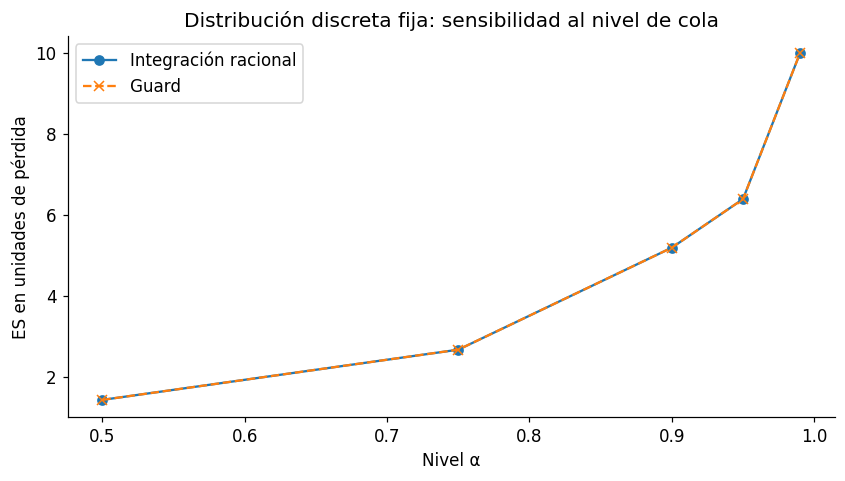

,threshold,status,breach,basis
0,3.999999999999999999,accepted,True,binary64-output
1,4,accepted,False,binary64-output
2,4.000000000000000001,accepted,False,binary64-output


In [10]:
from src.consumer import decide
threshold_rows=[]
for threshold in ['3.999999999999999999','4','4.000000000000000001']:
    packet=decide([0.,4.],threshold,.5,[1.,1.])
    threshold_rows.append(dict(threshold=threshold,status=packet['status'],
        breach=packet['breach'],basis=packet['comparison_basis']))
display(pd.DataFrame(threshold_rows))
assert threshold_rows[0]['breach'] is True
assert threshold_rows[1]['breach'] is False
assert threshold_rows[2]['breach'] is False
fig,ax=plt.subplots()
ax.plot(comparison.alpha,comparison.reference,'o-',label='Integración racional')
ax.plot(comparison.alpha,comparison.guard,'x--',label='Guard')
ax.set(xlabel='Nivel α',ylabel='ES en unidades de pérdida',title='Distribución discreta fija: sensibilidad al nivel de cola')
ax.legend();plt.show()

### 4. Límites del contrato
Las pruebas nuevas cubren coherencia discreta, transformaciones y umbrales ordinarios; no demuestran detección universal de pérdida de precisión. Un paquete internamente coherente puede provenir de datos falsos, y un ES correcto para la distribución de entrada no garantiza que esa distribución represente las pérdidas futuras. Estimación de colas, incertidumbre muestral y validación financiera requieren experimentos separados.

### Lectura de los resultados ejecutados

Las **60 distribuciones** del contraste cumplieron las propiedades de integración racional, transformación afín y escala de pesos con error inferior a **10⁻⁹**. En el experimento de umbrales, ES=4 supera la cadena decimal **3.999999999999999999**, pero no supera **4** ni **4.000000000000000001**. Esto comprueba la semántica estricta de la decisión sin confundir el float presentado con el umbral decimal.